In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks


In [2]:
#This step loads the transaction dataset into a pandas dataframe for preprocessing and feature extraction
df = pd.read_csv("training.csv")

print(df.shape)
df.head()


(95662, 16)


,TransactionId,BatchId,AccountId,SubscriptionId,CustomerId,CurrencyCode,CountryCode,ProviderId,ProductId,ProductCategory,ChannelId,Amount,Value,TransactionStartTime,PricingStrategy,FraudResult
0,TransactionId_76871,BatchId_36123,AccountId_3957,SubscriptionId_887,CustomerId_4406,UGX,256,ProviderId_6,ProductId_10,airtime,ChannelId_3,1000.0,1000,2018-11-15T02:18:49Z,2,0
1,TransactionId_73770,BatchId_15642,AccountId_4841,SubscriptionId_3829,CustomerId_4406,UGX,256,ProviderId_4,ProductId_6,financial_services,ChannelId_2,-20.0,20,2018-11-15T02:19:08Z,2,0
2,TransactionId_26203,BatchId_53941,AccountId_4229,SubscriptionId_222,CustomerId_4683,UGX,256,ProviderId_6,ProductId_1,airtime,ChannelId_3,500.0,500,2018-11-15T02:44:21Z,2,0
3,TransactionId_380,BatchId_102363,AccountId_648,SubscriptionId_2185,CustomerId_988,UGX,256,ProviderId_1,ProductId_21,utility_bill,ChannelId_3,20000.0,21800,2018-11-15T03:32:55Z,2,0
4,TransactionId_28195,BatchId_38780,AccountId_4841,SubscriptionId_3829,CustomerId_988,UGX,256,ProviderId_4,ProductId_6,financial_services,ChannelId_2,-644.0,644,2018-11-15T03:34:21Z,2,0


In [3]:
categorical_cols = [
    "ProviderId", "ProductCategory", "ChannelId", "PricingStrategy"
]

numerical_cols = [
    "Amount", "Value"
]

time_col = "TransactionStartTime"


In [4]:
#Temporal features were extracted because fraud patterns often occur during unusual times or days.”
df[time_col] = pd.to_datetime(df[time_col])

df["hour"] = df[time_col].dt.hour
df["dayofweek"] = df[time_col].dt.dayofweek


In [5]:
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])


In [7]:

from sklearn.preprocessing import RobustScaler
import numpy as np

feature_cols = categorical_cols + numerical_cols + ["hour", "dayofweek"]

# Explicit dtype conversion
df[feature_cols] = df[feature_cols].astype(np.float32)

# Scale
#RobustScaler was used because financial data contains outliers, and it scales features using the interquartile range
scaler = RobustScaler()
df.loc[:, feature_cols] = scaler.fit_transform(df[feature_cols])


In [8]:
#Transaction sequences were generated using a sliding window to allow the model to learn temporal patterns rather than isolated transactions.
#It provides sufficient temporal context while maintaining computational efficiency.
SEQ_LEN = 10

def create_sequences(data, seq_len):
    sequences = []
    for i in range(len(data) - seq_len):
        sequences.append(data[i:i+seq_len])
    return np.array(sequences)

X = create_sequences(df[feature_cols].values, SEQ_LEN)

print("Sequence shape:", X.shape)


Sequence shape: (95652, 10, 8)


In [9]:
X_train, X_val = train_test_split(
    X, test_size=0.2, shuffle=False
)

print(X_train.shape, X_val.shape)


(76521, 10, 8) (19131, 10, 8)


In [13]:
from tensorflow.keras import layers, models

def build_cnn_lstm_autoencoder(T, F):
    inputs = layers.Input(shape=(T, F))

    # CNN feature extraction (NO POOLING)
    #The convolution layer extracts local feature interactions within the transaction sequence, helping the model detect patterns across neighboring transactions
    x = layers.Conv1D(64, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    #The second convolution layer further refines extracted feature patterns and reduces dimensional complexity before passing the data to the recurrent network
    x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)

    # LSTM Encoder
    #The LSTM encoder learns temporal dependencies between transactions, capturing behavioral patterns across the transaction sequence
    encoded = layers.LSTM(64, return_sequences=True)(x)

    # LSTM Decoder
    decoded = layers.LSTM(64, return_sequences=True)(encoded)

    # Reconstruction
    # The TimeDistributed dense layer reconstructs each timestep of the transaction sequence, producing outputs with the same dimensionality as the input
    outputs = layers.TimeDistributed(layers.Dense(F))(decoded)

    model = models.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="mse")

    return model



In [14]:
def build_cnn_gru_autoencoder(T, F):
    inputs = layers.Input(shape=(T, F))

    x = layers.Conv1D(64, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)

    encoded = layers.GRU(64, return_sequences=True)(x)
    decoded = layers.GRU(64, return_sequences=True)(encoded)
#Produce Final Output sequence. This applies the Dense layer to each timestep independently.
    outputs = layers.TimeDistributed(layers.Dense(F))(decoded)
#The model is trained using the Adam optimizer and Mean Squared Error loss to measure reconstruction differences between original and reconstructed transaction sequences
    model = models.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="mse")
#Returns the constructed model so it can be trained
    return model


In [15]:
#Stops model training automatically when the model stops improving to avoid over fitting
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
#Both models learn normal transaction behavior and detect anomalies.
cnn_lstm = build_cnn_lstm_autoencoder(SEQ_LEN, X_train.shape[2])
cnn_gru  = build_cnn_gru_autoencoder(SEQ_LEN, X_train.shape[2])

history_lstm = cnn_lstm.fit(
    X_train, X_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop]
)

history_gru = cnn_gru.fit(
    X_train, X_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop]
)


Epoch 1/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 28s 19ms/step - loss: 127.8040 - val_loss: 983.0237
Epoch 2/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - loss: 113.1788 - val_loss: 938.1302
Epoch 3/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - loss: 103.1814 - val_loss: 899.7017
Epoch 4/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - loss: 95.2716 - val_loss: 866.5645
Epoch 5/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - loss: 88.4714 - val_loss: 836.0620
Epoch 6/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - loss: 82.9525 - val_loss: 808.9194
Epoch 7/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - loss: 77.5143 - val_loss: 782.8999
Epoch 8/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 39s 18ms/step - loss: 73.0901 - val_loss: 757.8950
Epoch 9/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - loss: 68.9823 - val_loss: 736.2257
Epoch 10/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - loss: 65.3416 - val_loss: 714.3263
Epoch 11/50
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - loss: 6

In [22]:

# Predict reconstruction on validation set
X_val_pred_lstm = cnn_lstm.predict(X_val)
X_val_pred_gru  = cnn_gru.predict(X_val)

# Compute reconstruction errors
recon_err_lstm = np.mean(np.square(X_val - X_val_pred_lstm), axis=(1, 2))
recon_err_gru  = np.mean(np.square(X_val - X_val_pred_gru), axis=(1, 2))

# Define thresholds (99th percentile – standard choice)
lstm_threshold = np.percentile(recon_err_lstm, 99)
gru_threshold  = np.percentile(recon_err_gru, 99)

print("LSTM Threshold:", lstm_threshold)
print("GRU Threshold:", gru_threshold)



598/598 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step
598/598 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
LSTM Threshold: 214.21521
GRU Threshold: 11326.3545


In [23]:
# Predict reconstruction on validation set
X_val_pred_lstm = cnn_lstm.predict(X_val)
X_val_pred_gru  = cnn_gru.predict(X_val)

# Compute reconstruction errors
recon_err_lstm = np.mean(np.square(X_val - X_val_pred_lstm), axis=(1, 2))
recon_err_gru  = np.mean(np.square(X_val - X_val_pred_gru), axis=(1, 2))

# Apply thresholds
y_pred_lstm = (recon_err_lstm > lstm_threshold).astype(int)
y_pred_gru  = (recon_err_gru  > gru_threshold).astype(int)

# DISPLAY RESULTS 
print("CNN-LSTM Anomalies Detected:", np.sum(y_pred_lstm))
print("CNN-GRU Anomalies Detected:", np.sum(y_pred_gru))
print("Total Validation Samples:", len(X_val))


598/598 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
598/598 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
CNN-LSTM Anomalies Detected: 192
CNN-GRU Anomalies Detected: 192
Total Validation Samples: 19131


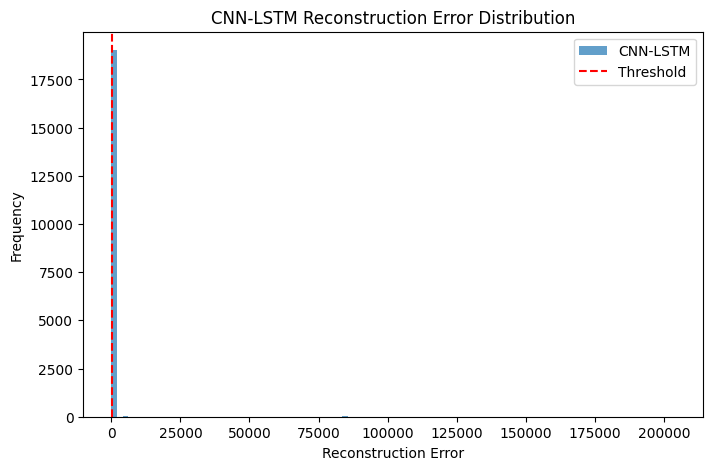

In [24]:

# Reconstruction Error Distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(recon_err_lstm, bins=100, alpha=0.7, label="CNN-LSTM")
plt.axvline(lstm_threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.title("CNN-LSTM Reconstruction Error Distribution")
plt.legend()
plt.show()


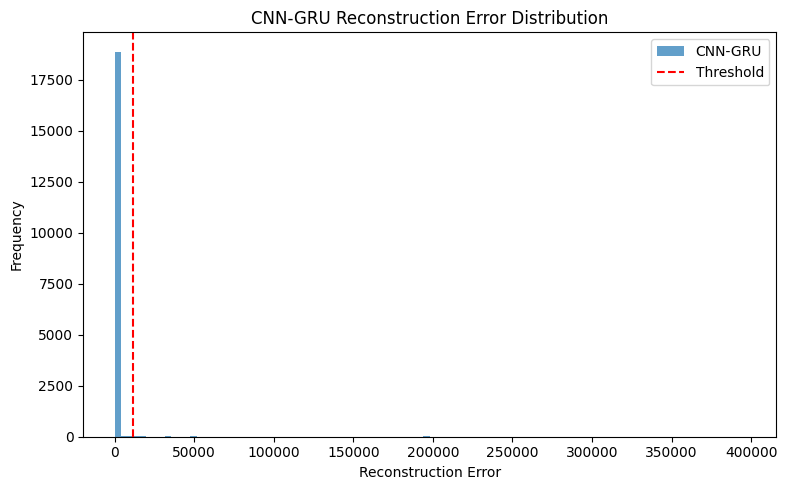

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(recon_err_gru, bins=100, alpha=0.7, label="CNN-GRU")
plt.axvline(gru_threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.title("CNN-GRU Reconstruction Error Distribution")
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
# Anomaly Rate Table
anom_rate_lstm = np.mean(y_pred_lstm) * 100
anom_rate_gru  = np.mean(y_pred_gru) * 100

print(f"CNN-LSTM Anomaly Rate: {anom_rate_lstm:.2f}%")
print(f"CNN-GRU Anomaly Rate: {anom_rate_gru:.2f}%")


CNN-LSTM Anomaly Rate: 1.00%
CNN-GRU Anomaly Rate: 1.00%


In [27]:
# Do the Models Flag the SAME Transactions? (VERY STRONG ANALYSIS)
overlap = np.sum((y_pred_lstm == 1) & (y_pred_gru == 1))
print("Overlapping anomalies:", overlap)


Overlapping anomalies: 152


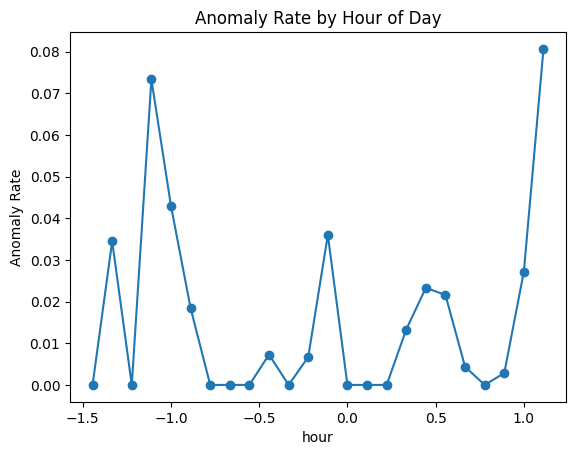

In [28]:
# Time-of-Day Anomaly Pattern (DOMAIN-SPECIFIC)

df_val = df.iloc[-len(y_pred_lstm):].copy()
df_val["anomaly"] = y_pred_lstm

hourly_anom = df_val.groupby("hour")["anomaly"].mean()

hourly_anom.plot(marker="o", title="Anomaly Rate by Hour of Day")
plt.ylabel("Anomaly Rate")
plt.show()


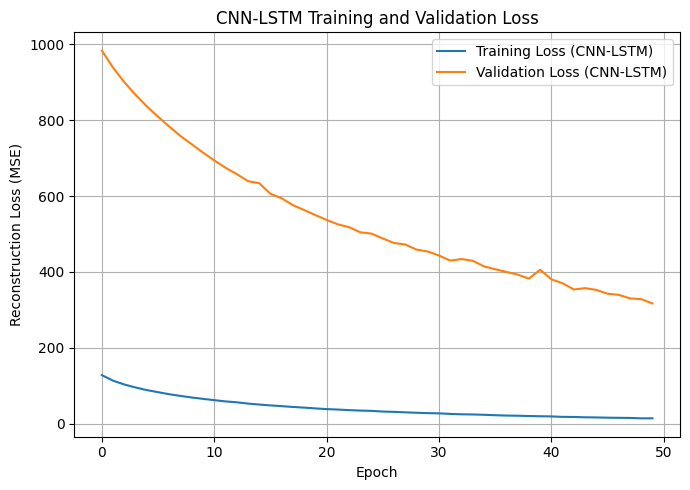

In [29]:
# CNN-LSTM Loss Curve
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.plot(history_lstm.history["loss"], label="Training Loss (CNN-LSTM)")
plt.plot(history_lstm.history["val_loss"], label="Validation Loss (CNN-LSTM)")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss (MSE)")
plt.title("CNN-LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


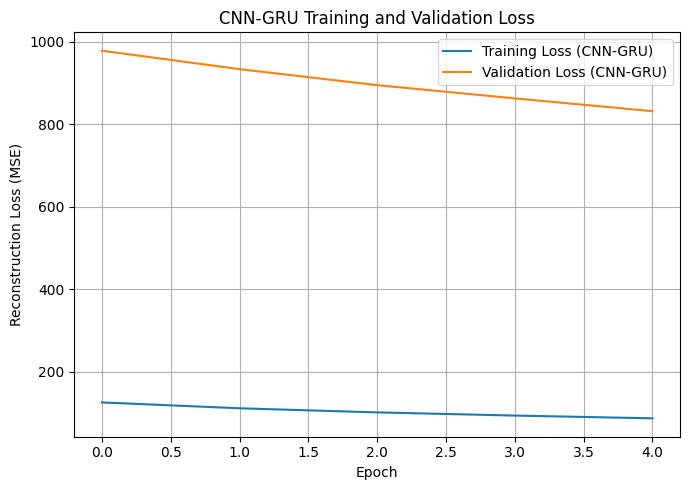

In [30]:
# CNN-GRU Loss Curve
plt.figure(figsize=(7,5))
plt.plot(history_gru.history["loss"], label="Training Loss (CNN-GRU)")
plt.plot(history_gru.history["val_loss"], label="Validation Loss (CNN-GRU)")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss (MSE)")
plt.title("CNN-GRU Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:
# Compute Key Statistics
import pandas as pd
import numpy as np
import time

# Anomaly rates
anom_rate_lstm = np.mean(y_pred_lstm) * 100
anom_rate_gru  = np.mean(y_pred_gru)  * 100

# Mean reconstruction error
mean_err_lstm = np.mean(recon_err_lstm)
mean_err_gru  = np.mean(recon_err_gru)

# Build table
performance_table = pd.DataFrame({
    "Metric": [
        "Anomaly Rate (%)",
        "Mean Reconstruction Error",
        "Reconstruction Error Threshold",
        "Training Stability",
        "Model Complexity"
    ],
    "CNN-LSTM": [
        f"{anom_rate_lstm:.2f}",
        f"{mean_err_lstm:.2f}",
        f"{lstm_threshold:.2f}",
        "High",
        "Higher"
    ],
    "CNN-GRU": [
        f"{anom_rate_gru:.2f}",
        f"{mean_err_gru:.2f}",
        f"{gru_threshold:.2f}",
        "Moderate",
        "Lower"
    ]
})

performance_table


,Metric,CNN-LSTM,CNN-GRU
0,Anomaly Rate (%),1.00,1.00
1,Mean Reconstruction Error,316.93,978.07
2,Reconstruction Error Threshold,214.22,11326.35
3,Training Stability,High,Moderate
4,Model Complexity,Higher,Lower
